# main: run the whole project in order

**Purpose.** One entry point that runs every step of the project top to bottom, so the results can be rebuilt with
*Restart, Run All* on this notebook only.

**Input.** Nothing beyond the repository and internet access for the first run (notebook 01 downloads the SEC and
FRED data; it needs `sec_user_agent.txt` in the repository root or the environment variable `SEC_USER_AGENT`, see
README).

**Output.** Everything the step notebooks write: `data/processed/`, `output/tables/`, `output/figures/`.

**Steps.**
1. `01_preprocess.ipynb`: working dataset of new BDC loans (about 46 minutes here on a laptop, 10 to 20 minutes
   when run alone, longer on the first run; peak memory about 2.6 GB).
2. `02_estimate.ipynb`: baselines and models on the validation folds, choice of the main model, test and robustness
   predictions for notebook 03 (about 2 minutes; summary in `docs/model_report.md`).
3. `03_evaluate.ipynb`: final evaluation on the test quarters, used once: metrics of the main model and the baselines
   overall, by quarter and by manager family, bootstrap interval, sensitivity and robustness (seconds; summary in
   `docs/evaluation_report.md`).

## Step 1: preprocessing

project folder: DSF_Project
2022q4_bdc.zip     11.9
2023q1_bdc.zip     16.7
2023q2_bdc.zip     20.4
2023q3_bdc.zip     21.9
2023q4_bdc.zip     23.4
2024q1_bdc.zip     30.6
2024q2_bdc.zip     24.1
2024q3_bdc.zip     25.8
2024q4_bdc.zip     27.5
2025q1_bdc.zip     36.9
2025q2_bdc.zip     29.7
2025q3_bdc.zip     31.7
2025q4_bdc.zip     34.5
2026_01_bdc.zip     0.9
2026_02_bdc.zip    16.0
2026_03_bdc.zip    29.0
2026_04_bdc.zip     1.1
2026_05_bdc.zip    41.0
2026_06_bdc.zip     0.1
2026_07_bdc.zip     2.5
2026_08_bdc.zip    75.9
2026_09_bdc.zip     0.4
2026_10_bdc.zip     1.8


rows: 2035844  filings (adsh): 2310  BDCs (cik): 204
source_file
2022q4_bdc.zip      48
2023q1_bdc.zip      62
2023q2_bdc.zip     124
2023q3_bdc.zip     135
2023q4_bdc.zip     139
2024q1_bdc.zip     140
2024q2_bdc.zip     151
2024q3_bdc.zip     154
2024q4_bdc.zip     156
2025q1_bdc.zip     160
2025q2_bdc.zip     166
2025q3_bdc.zip     165
2025q4_bdc.zip     179
2026_01_bdc.zip      2
2026_02_bdc.zip     52
2026_03_bdc.zip    119
2026_04_bdc.zip      4
2026_05_bdc.zip    173
2026_07_bdc.zip      6
2026_08_bdc.zip    169
2026_09_bdc.zip      2
2026_10_bdc.zip      4
kept rows: current period 1072616 + comparatives 701289


period-end months: {2: 1237, 3: 277813, 5: 1847, 6: 290617, 7: 215, 8: 2441, 9: 245044, 11: 1576, 12: 251826}


BDC-quarters with more than one filing: 12 (kept the latest filing)


         bdcs  filings   rows
quarter                      
2022Q3     49       49  31027
2022Q4     65       65  29841
2023Q1    123      123  47675
2023Q2    134      134  49342
2023Q3    140      140  53639
2023Q4    143      143  55655
2024Q1    149      149  59650
2024Q2    154      154  63475
2024Q3    158      158  68507
2024Q4    160      160  71487
2025Q1    165      165  75627
2025Q2    165      165  80294
2025Q3    167      167  87288
2025Q4    173      173  93515
2026Q1    174      174  96098
2026Q2    175      175  99257


BDCs: 204  families: 103  families with >1 BDC: 45
family
AG Twin Brook                                                                  [AG TWIN BROOK BDC, INC., TPG TWIN BROOK CAPITAL INCOME FUND]
AllianceBernstein                                                                [AB PRIVATE CREDIT INVESTORS CORP, AB PRIVATE LENDING FUND]
Antares                                   [ANTARES PRIVATE CREDIT FUND, ANTARES STRATEGIC CREDIT FUND, ANTARES STRATEGIC CREDIT FUND II LLC]
Apollo               [APOLLO DEBT SOLUTIONS BDC, APOLLO ORIGINATION II (LEVERED) CAPITAL TRUST, APOLLO ORIGINATION II (UL) CAPITAL TRUST,...
Ares                                                          [ARES CAPITAL CORP, ARES CORE INFRASTRUCTURE FUND, ARES STRATEGIC INCOME FUND]
Audax                                                                                [AUDAX CREDIT BDC INC., AUDAX PRIVATE CREDIT FUND, LLC]
BC Partners                                                       [BC PARTNERS LENDING CORP, BCP

... (15 outputs left out)

loans.csv: display names cleaned for 31 loans
loans_all_bdc.csv: display names cleaned for 35 loans


loans_incl_refi.csv: display names cleaned for 34 loans
variant incl. refinancings: (2170, 56)


core: (1705, 54)  all-BDC: (6979, 54)
       loans   first    last
split                       
test     583  2025Q3  2026Q2
train   1122  2023Q2  2025Q2
       spread_pp  tenor_years  log_principal  baa_spread_prev  sofr_prev  mkt_spread_t2_all
count    1705.00      1705.00        1705.00          1705.00    1705.00            1705.00
mean        4.81         6.33          16.14             1.66       4.70               5.13
std         1.22         0.84           1.47             0.14       0.56               0.55
min         1.75         4.06          11.51             1.42       3.68               4.50
25%         4.10         5.67          15.20             1.55       4.41               4.75
50%         5.00         6.23          16.18             1.67       4.49               5.00
75%         5.50         7.12          17.11             1.76       5.33               5.50
max         9.50         7.50          20.48             2.11       5.38               6.75
missing values (co

             n  share_acquired_earlier
tenor_bin                             
(0, 2]      22                   0.455
(2, 3]      30                   0.133
(3, 4]      65                   0.123
(4, 5]      95                   0.105
(5, 6]     175                   0.069
(6, 7]     129                   0.093
(7, 8]     136                   0.059
(8, 40]      1                   0.000
      count   25%   50%   75%
year                         
2023  179.0  5.75  6.25  6.55
2024  653.0  4.25  5.00  5.50
2025  603.0  4.00  4.75  5.25
2026  270.0  3.25  4.50  5.00
                        count   25%   50%   75%
sector                                         
Industrials             504.0  4.50  5.00  5.50
Information Technology  267.0  4.50  5.00  5.62
Health Care             265.0  4.50  5.00  5.50
Consumer Discretionary  231.0  4.25  5.00  5.75
Financials              139.0  3.25  4.50  5.25
Consumer Staples         80.0  4.50  5.00  5.75
Materials                75.0  3.50  4.75  5.2

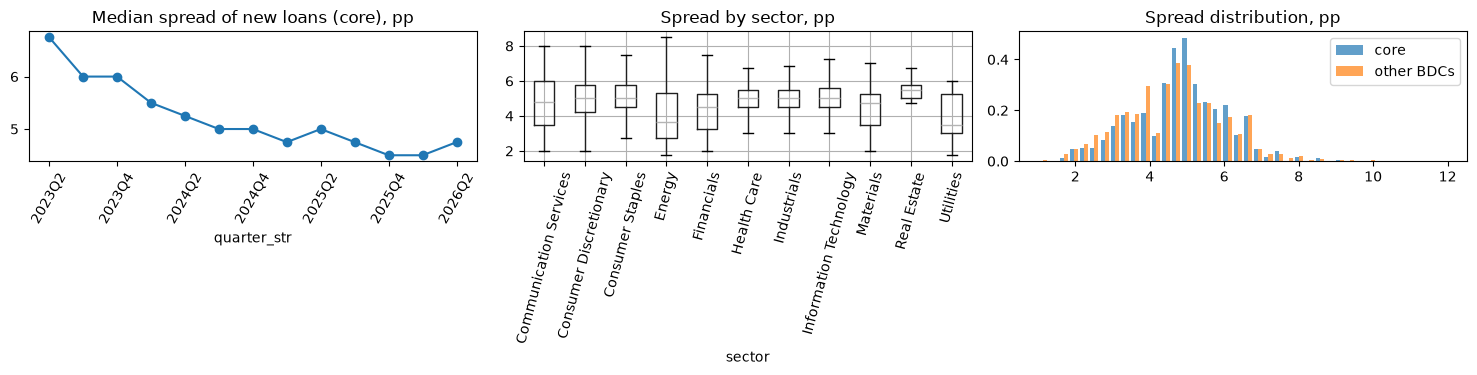

                         feature                                                           value fixed by                            check
                     tenor_years                              computed from quarter_start (contract term)                  by construction
                   log_principal held principal at the reporting date (approximation of the planned hold)                  by construction
sector, lien, instrument, family                  contract characteristics, fixed when the deal is signed                  by construction
      baa_spread_prev, sofr_prev                                    FRED value dated before quarter_start                             True
               mkt_spread_t2_all                          loans of quarter t-2 filed before quarter_start asserted below for every quarter
t-2 market median and FRED dates checked for 13 quarters
checked loans whose loan_id changed since the check (family re-mapping): 5
hand-checked loans: 50  families: 

verification sample: 30  in the final sample: 29  classes: {'a': 24, 'b': 5, 'not new (restructuring)': 1}
hand check v2: 50  in the final sample: 50  classes: {'a': 47, 'b': 3}
loans checked more than once: 0
                                                   sample class   n  share  ci_low  ci_high
                                         all checked (50)     a  35  0.700   0.562    0.809
                                         all checked (50)     b  14  0.280   0.175    0.417
                                         all checked (50)     c   1  0.020   0.004    0.105
                                     in final sample (36)     a  32  0.889   0.747    0.956
                                     in final sample (36)     b   3  0.083   0.029    0.218
                                     in final sample (36)     c   1  0.028   0.005    0.142
                            Patrick, in final sample (26)     a  25  0.962   0.811    0.993
                            Patrick, in final sample (

                                                                                        item  value  ci_low  ci_high     n          note
                                                                           loans (loans.csv)   1705     NaN      NaN   NaN              
                                                                               first quarter 2023Q2     NaN      NaN   NaN              
                                                                                last quarter 2026Q2     NaN      NaN   NaN              
                                                              train loans (2023Q2 to 2025Q2)   1122     NaN      NaN   NaN              
                                                               test loans (2025Q3 to 2026Q2)    583     NaN      NaN   NaN              
                                                                           test loans 2025Q3    164     NaN      NaN   NaN              
                                         

In [1]:
%run 01_preprocess.ipynb

## Step 2: estimation

project folder: DSF_Project | pandas 3.1.1 | scikit-learn 1.9.1
 fold validation_quarter  n_train   train_quarters  n_validation
    0             2024Q3      295 2023Q2 to 2024Q1           180
    1             2024Q4      447 2023Q2 to 2024Q2           205
    2             2025Q1      627 2023Q2 to 2024Q3           151
    3             2025Q2      830 2023Q2 to 2024Q4           139
validation loans whose manager family is not in the training part of their fold: 61 (encoded as the pooled infrequent group)
training rows: 1122 (test rows not used: 583); validation loans over the 4 folds: 675
                                      n  mae_bps  share_within_50bps  mae_fold0_2024Q3  mae_fold1_2024Q4  mae_fold2_2025Q1  mae_fold3_2025Q2  fold_spread_bps
model                                                                                                                                                        
Baseline 1: market median t-2     675.0     78.6               0.584              77

quarter  baseline_1  median_all_bdc_file_t-2  n_loans_t-2
 2024Q3        5.00                     5.00          547
 2024Q4        5.00                     5.00          671
 2025Q1        5.00                     5.00          650
 2025Q2        4.75                     4.75          728


baseline 2 recomputed by hand for all 675 validation loans: identical to the helper
sector x size cell         634
fallback: sector median     33
fallback: baseline 1         8


Linear regression: 74.9 bps


Ridge: default 72.3 bps, tuned 72.2 bps with {'alpha': 3} (9 settings x 4 folds, 0.5 s)


Lasso: default 96.0 bps, tuned 68.5 bps with {'alpha': 0.01} (8 settings x 4 folds, 0.4 s)
alpha     3.0   1.0   1.0  10.0  30.0   0.1  100.0  300.0  1000.0
mae_bps  72.2  72.3  72.3  72.8  73.1  74.3   74.8   80.3    87.4
alpha     0.01   0.03   0.003   0.001   0.1   0.0003   1.0   1.0
mae_bps  68.50  69.20  69.300  72.500  73.1  74.0000  96.0  96.0
ridge: best alpha 3 inside the grid
lasso: best alpha 0.01 inside the grid
lasso (last fold): 15 of 43 coefficients not zero; set to zero: ['cat__sector_Consumer Discretionary', 'cat__sector_Consumer Staples', 'cat__sector_Energy', 'cat__sector_Financials', 'cat__sector_Health Care', 'cat__sector_Materials', 'cat__sector_Real Estate', 'cat__sector_infrequent_sklearn', 'cat__lien_first_lien_last_out', 'cat__lien_infrequent_sklearn', 'cat__family_Bain Capital', 'cat__family_BlackRock', 'cat__family_Brightwood Capital Corp I', 'cat__family_Comvest', 'cat__family_Crescent', 'cat__family_Diameter Credit Co', 'cat__family_Jefferies', 'cat__famil

... (9 outputs left out)

Boosting (residual): default 58.3 bps, tuned 58.3 bps with {'learning_rate': 0.1, 'n_estimators': 100, 'max_depth': 3} (9 settings x 4 folds, 3.7 s)


Neural network (residual): default 60.8 bps, tuned 60.8 bps with {'hidden_layer_sizes': (100,), 'alpha': 0.0001} (7 settings x 4 folds, 3.8 s)
ridge (residual): best alpha 100 inside the grid
lasso (residual): best alpha 0.03 inside the grid
                                      n  mae_bps  share_within_50bps  mae_fold0_2024Q3  mae_fold1_2024Q4  mae_fold2_2025Q1  mae_fold3_2025Q2  fold_spread_bps  folds_beating_baseline_1  gain_vs_baseline_1_bps
model                                                                                                                                                                                                          
Boosting (residual)               675.0     58.3               0.576              55.1              57.3              60.4              61.5              6.4                         4                    20.2
Random forest (residual)          675.0     59.3               0.573              57.9              55.9              62.6            

                    model  committed_features_mae  with_optional_features_mae  gain_bps  fold_spread_bps  gain_larger_than_fold_spread
      Boosting (residual)                    58.3                        57.3       1.0              6.4                         False
 Random forest (residual)                    59.3                        54.6       4.7              6.8                         False
Neural network (residual)                    60.8                        68.3      -7.5              7.9                         False
updated: predictions_validation.csv, 20 models; horse_race_validation.csv; written: optional_features_validation.csv
mean error per validation quarter in bps (positive = prediction too low; compare 6f):
quarter                                       2024Q3  2024Q4  2025Q1  2025Q2
model                                                                       
Boosting (residual, optional features)          11.4    19.0    20.6    11.7
Neural network (residual, 

                                                   mae_bps  share_within_50bps  fold_spread_bps  mae_fold0_2024Q3  mae_fold1_2024Q4  mae_fold2_2025Q1  mae_fold3_2025Q2
model                                                                                                                                                                  
Random forest (residual, optional features)           54.6               0.631              7.0              55.7              52.9              51.6              58.6
Random forest (residual, revolver + delayed draw)     54.9               0.630              7.3              55.4              53.3              52.1              59.4
Random forest (residual)                              59.3               0.573              6.8              57.9              55.9              62.6              62.7
mean error per validation quarter in bps (positive = prediction too low):
quarter
2024Q3     8.1
2024Q4    18.4
2025Q1    13.4
2025Q2    24.4
Freq: Q-DEC


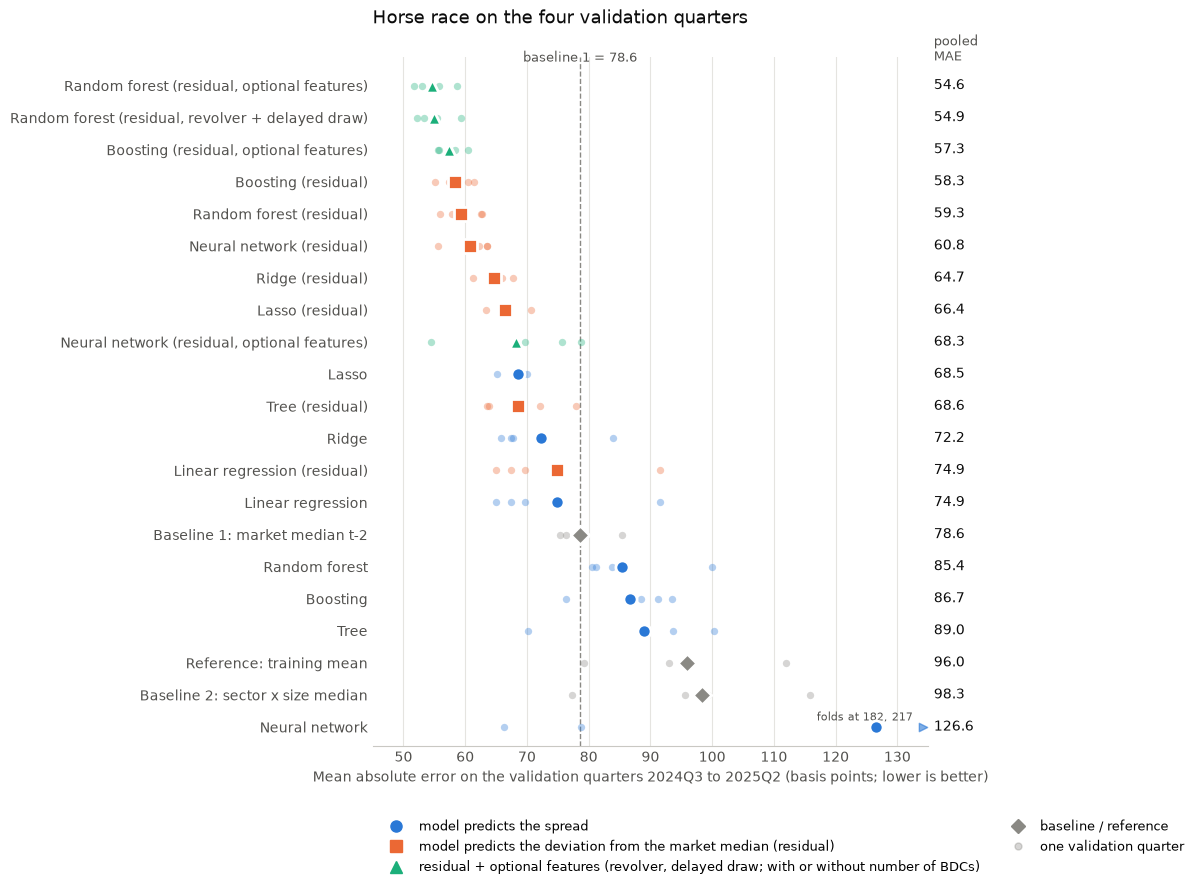

main_model                                                                                                     Random forest (residual, revolver + delayed draw)
decided_by                                                                                                                notebook 02 owner (E10, D49; E11, D51)
decided_on                                                                                                                                            2026-11-21
estimator                                                                                                                                  RandomForestRegressor
params                                                      {'n_estimators': 300, 'random_state': 42, 'n_jobs': -1, 'max_features': 0.33, 'min_samples_leaf': 1}
training_target                                                                           spread_pp - mkt_spread_t2_all (prediction adds mkt_spread_t2_all back)
features                         l

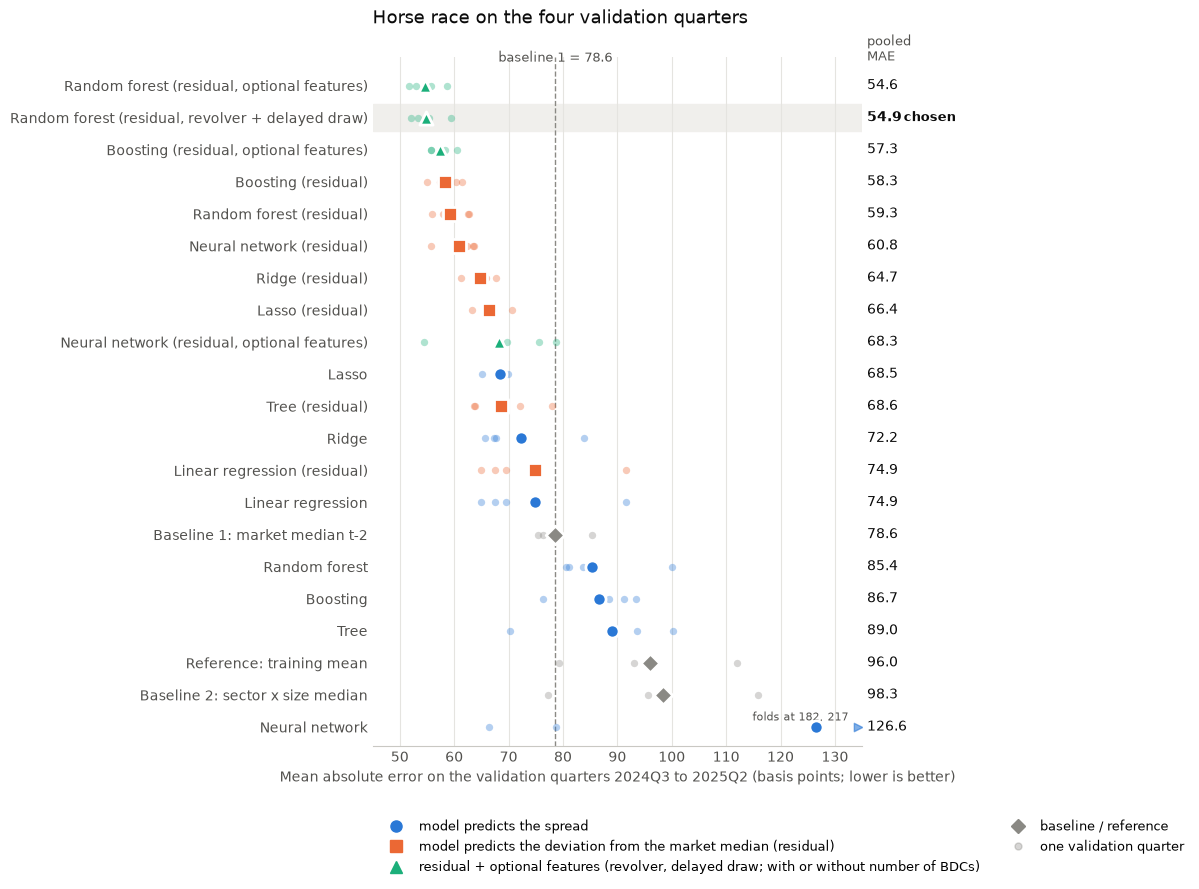

tenor_years          0.242
log_principal        0.238
family               0.162
has_revolver         0.093
sector               0.075
mkt_spread_t2_all    0.050
baa_spread_prev      0.043
sofr_prev            0.041
lien                 0.032
has_delayed_draw     0.024


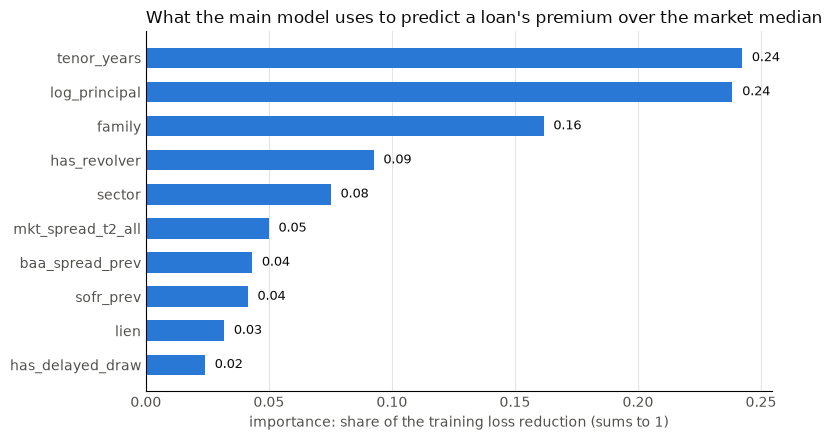

test quarter 2025Q3: train on 983 loans up to 2025Q1, predict 164 loans
test quarter 2025Q4: train on 1122 loans up to 2025Q2, predict 149 loans
test quarter 2026Q1: train on 1286 loans up to 2025Q3, predict 147 loans
test quarter 2026Q2: train on 1435 loans up to 2025Q4, predict 123 loans


written: data/processed/predictions_test.csv, 12826 rows = 22 models x 583 test loans (no test error computed here)


all BDCs, without sector (loans_all_bdc.csv): 2261 test loans predicted by the main model and baseline 1


including refinancings and add-ons (loans_incl_refi.csv): 759 test loans predicted by the main model and baseline 1
written: data/processed/predictions_robustness.csv, 6040 rows (no test error computed here)


In [2]:
%run 02_estimate.ipynb

## Step 3: evaluation on the test quarters

project folder: DSF_Project | pandas 3.1.1
main model (chosen on validation, D49/D51): Random forest (residual, revolver + delayed draw)
candidates in the test file: 22 | test loans: 583
quarter
2025Q3    164
2025Q4    149
2026Q1    147
2026Q2    123
                                            model  n_test  test_mae_bps  test_share_within_50bps  test_mean_error_bps  validation_mae_bps  validation_share_within_50bps  test_minus_validation_mae_bps
Random forest (residual, revolver + delayed draw)     583          58.1                    0.554                 -1.7                54.9                          0.630                            3.2
                    Baseline 1: market median t-2     583          86.3                    0.503                -27.8                78.6                          0.584                            7.7
                 Baseline 2: sector x size median     583          79.9                    0.537                -24.0                98.3            

model    Random forest (residual, revolver + delayed draw)  Baseline 1: market median t-2  Baseline 2: sector x size median  Reference: training mean
quarter                                                                                                                                              
2025Q3                                                54.3                           82.0                              82.0                      86.8
2025Q4                                                48.1                           68.5                              67.5                      78.8
2026Q1                                                61.9                           97.6                              84.6                     107.1
2026Q2                                                70.6                          100.0                              86.5                      98.3

mean error (bps; positive = predicted too low)
model    Random forest (residual, revolver + delayed

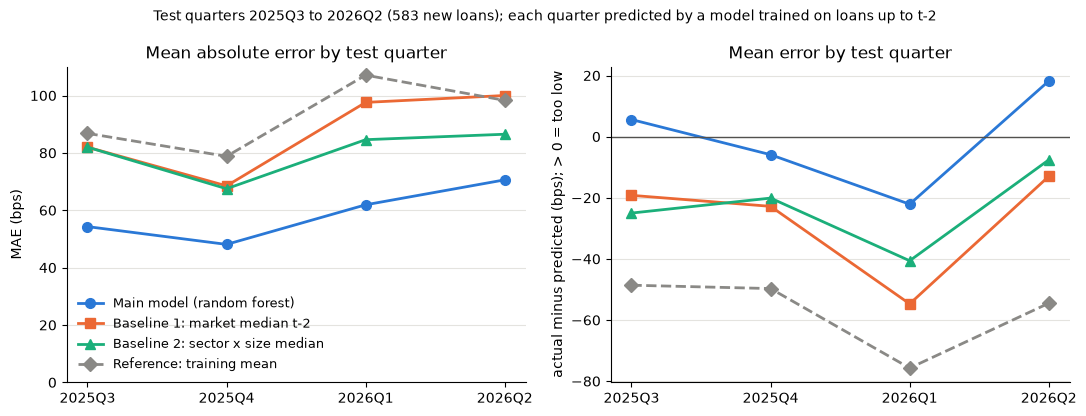

                                       comparison  gap_mae_bps  ci95_low_bps  ci95_high_bps  share_of_draws_model_better  gap_2025Q3_bps  gap_2025Q4_bps  gap_2026Q1_bps  gap_2026Q2_bps
   main model minus Baseline 1: market median t-2        -28.2         -33.3          -23.1                          1.0           -27.7           -20.4           -35.7           -29.4
main model minus Baseline 2: sector x size median        -21.8         -26.7          -17.0                          1.0           -27.7           -19.4           -22.7           -15.8
        main model minus Reference: training mean        -34.2         -39.9          -28.4                          1.0           -32.5           -30.7           -45.2           -27.6
                        family  n  main_mae_bps  baseline_1_mae_bps  gap_bps  main_share_within_50bps  main_mean_error_bps
                        Apollo 94          63.7                95.5    -31.8                    0.532                 -7.0
             A

                                     variant    n  gap_mae_bps  ci95_low_bps  ci95_high_bps
                 main sample, all test loans  583        -28.2         -33.3          -23.1
 main sample without likely syndicated loans  336        -24.4         -30.7          -18.5
                        all BDCs (no sector) 2261        -27.8         -30.4          -25.1
incl. refinancings, add-ons, tenor 3-4 years  759        -33.1         -37.9          -28.5


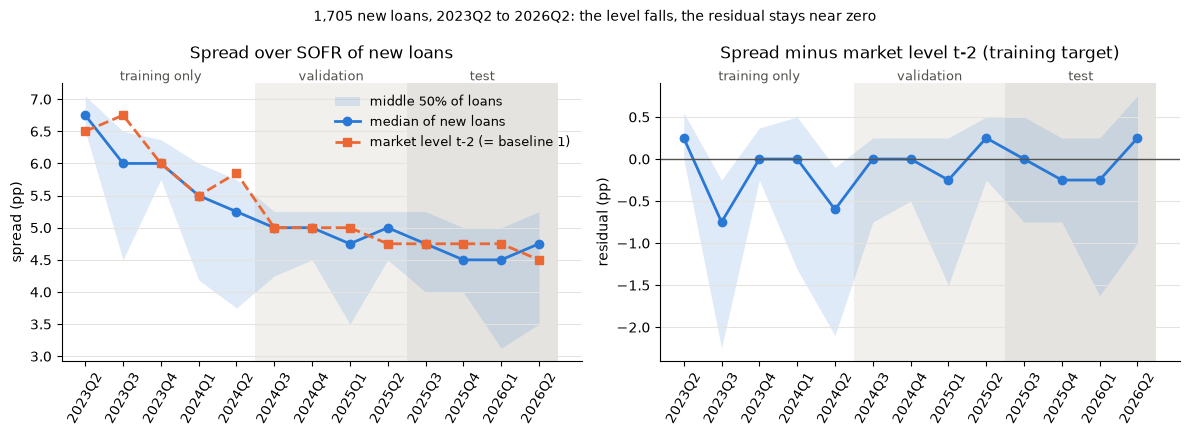

               n   med   mkt  r_med
quarter_str                        
2023Q2        39  6.75  6.50   0.25
2023Q3        55  6.00  6.75  -0.75
2023Q4        85  6.00  6.00   0.00
2024Q1       116  5.50  5.50   0.00
2024Q2       152  5.25  5.85  -0.60
2024Q3       180  5.00  5.00   0.00
2024Q4       205  5.00  5.00   0.00
2025Q1       151  4.75  5.00  -0.25
2025Q2       139  5.00  4.75   0.25
2025Q3       164  4.75  4.75   0.00
2025Q4       149  4.50  4.75  -0.25
2026Q1       147  4.50  4.75  -0.25
2026Q2       123  4.75  4.50   0.25


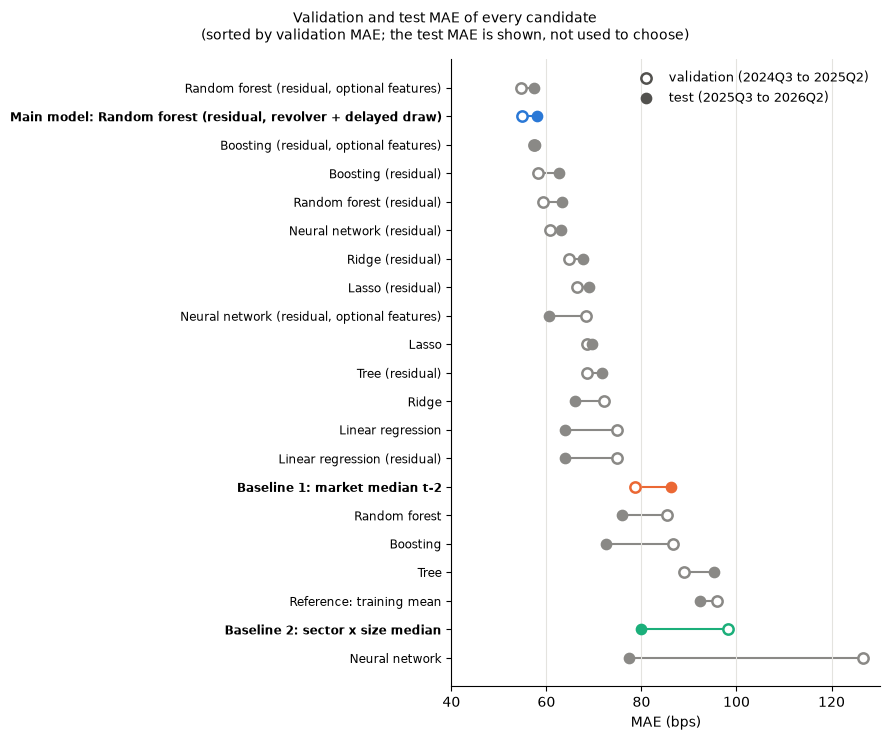

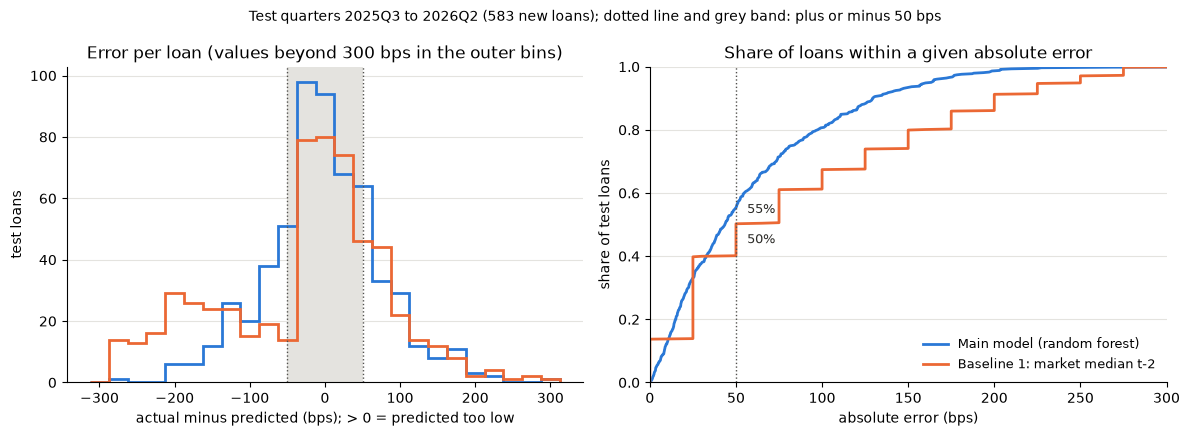

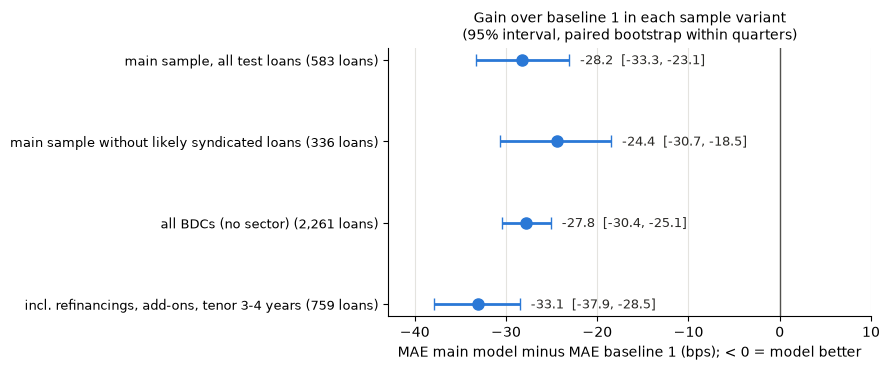

main model: test MAE 58.1 bps (validation 54.9), 55.4% within 50 bps
baseline 1: test MAE 86.3 bps, 50.3% within 50 bps
gap main minus baseline 1: -28.2 bps, 95% interval -33.3 to -23.1
all outputs written: 13


In [3]:
%run 03_evaluate.ipynb

## Check

In [4]:
import pandas as pd
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "code" else Path.cwd()
h = pd.read_csv(ROOT / "output" / "tables" / "headline_numbers.csv")
print(h[["item", "value"]].head(8).to_string(index=False))
# Check: the main output exists and has the number of rows reported in the headline table.
assert len(pd.read_csv(ROOT / "data" / "processed" / "loans.csv")) == int(h.set_index("item").loc["loans (loans.csv)", "value"])
# Check: notebook 02 recorded the main model and wrote one test prediction per model and test loan.
choice = pd.read_csv(ROOT / "output" / "tables" / "model_choice.csv")
test_pred = pd.read_csv(ROOT / "data" / "processed" / "predictions_test.csv")
n_test = (pd.read_csv(ROOT / "data" / "processed" / "loans.csv")["split"] == "test").sum()
assert len(choice) == 1 and (test_pred.groupby("model")["loan_id"].nunique() == n_test).all()
print("main model:", choice.loc[0, "main_model"], "| validation MAE (bps):", choice.loc[0, "validation_mae_bps"])
# Check: notebook 03 evaluated the recorded main model on every test loan.
head = pd.read_csv(ROOT / "output" / "tables" / "test_headline.csv").set_index("model")
assert head.loc[choice.loc[0, "main_model"], "n_test"] == n_test
print("test MAE (bps): main model", head.loc[choice.loc[0, "main_model"], "test_mae_bps"],
      "| baseline 1", head.loc["Baseline 1: market median t-2", "test_mae_bps"])

                          item  value
             loans (loans.csv)   1705
                 first quarter 2023Q2
                  last quarter 2026Q2
train loans (2023Q2 to 2025Q2)   1122
 test loans (2025Q3 to 2026Q2)    583
             test loans 2025Q3    164
             test loans 2025Q4    149
             test loans 2026Q1    147
main model: Random forest (residual, revolver + delayed draw) | validation MAE (bps): 54.9
test MAE (bps): main model 58.1 | baseline 1 86.3
